# Descriptives

## TOC 

- [Setup & Git](#setup)
- [Load and Preprocess Kern et al. & GPT Tweets](#load_preprocess_tweets)
- [Compare Prevalences](#compare_prevalences)
- [Check for Order Effects](#order_effects)

# Stuff to Check For / Analysis Ideas
- compare prevalences with those from Kern et al Paper 
- calculate agreement per tweets across the different conditions
- order effects (compare batch prompted with single-tweet prompted tweets)
- compare uncertainty measures per conditions (empirical entropy, confidence scores, etc.)

<a id="setup"></a>
## Setup & Git

In [1]:
# General Setup and Git
# cd to path of current script
import os
import sys
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
os.chdir(sys.path[0])

! git pull

Already up to date.


In [2]:
# Git codes
## see git status
! git status # see git status

# Ask the user for a commit message
commit_message = input("Enter commit message: ")

## Git add the current stuff to commit and set commit message
! git add .
! git commit -m "$commit_message"

## Push commits to remote
! git push

On branch master
Your branch is up to date with 'origin/master'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   .ipynb_checkpoints/4a_GPT_Labeling-checkpoint.ipynb
	modified:   .ipynb_checkpoints/4b_GPT_Label_Descriptives-checkpoint.ipynb
	modified:   .ipynb_checkpoints/utils-checkpoint.py
	modified:   .jupyter/desktop-workspaces/default-37a8.jupyterlab-workspace
	modified:   4a_GPT_Labeling.ipynb
	modified:   4b_GPT_Label_Descriptives.ipynb
	modified:   __pycache__/utils.cpython-311.pyc
	modified:   utils.py

no changes added to commit (use "git add" and/or "git commit -a")


Enter commit message:  Updates for Descriptives 


[master e046538] Updates for Descriptives
 8 files changed, 6394 insertions(+), 2992 deletions(-)
 rewrite .ipynb_checkpoints/4b_GPT_Label_Descriptives-checkpoint.ipynb (86%)
 rewrite .jupyter/desktop-workspaces/default-37a8.jupyterlab-workspace (92%)
 rewrite 4b_GPT_Label_Descriptives.ipynb (86%)
 rewrite __pycache__/utils.cpython-311.pyc (64%)
Enumerating objects: 22, done.
Counting objects: 100% (21/21), done.
Delta compression using up to 8 threads
Compressing objects: 100% (11/11), done.
Writing objects: 100% (12/12), 296.25 KiB | 4.63 MiB/s, done.
Total 12 (delta 7), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (7/7), completed with 6 local objects.
To github.com:T-Reiter/master-thesis.git
   0b0e6be..e046538  master -> master


<a id="load_preprocess_tweets"></a>
## Load and Preprocess the GPT Labelled Tweets

### Load the AS Paper tweets from Kern et al. (2023)

In [49]:
# load the full tweets as used by CK
import pandas as pd
# pd.set_option('max_colwidth', 1000)
pd.set_option('display.max_colwidth', 0)

# Load the tweet files
folder_path = 'Tweets_CK/'
train_file = 'full_train_s.csv'
test_file = 'full_test_s.csv'

train_df = pd.read_csv(os.path.join(folder_path, train_file))
test_df = pd.read_csv(os.path.join(folder_path, test_file))

# Reorder test_df columns to match train_df
test_df = test_df[train_df.columns]

# Add the 'original_split' column
train_df['original_split'] = 'train'
test_df['original_split'] = 'test'

# Combine them
tweets_full = pd.concat([train_df, test_df], ignore_index=True)

# Rename columns for a consistent style 
tweets_full = (tweets_full.
               rename(columns={'tweet.id': 'tweet_id', 
                               'batch.tweet': 'batch_tweet',
                               'hate.speech': 'hate_speech', 
                               'offensive.language': 'offensive_language'}))

tweets_full.head(2)

,tweet_id,id,version,batch_tweet,hate_speech,offensive_language,tweet_hashed,original_split
0,1449,1069,E,R49,1.0,1.0,"Subtweeting little bitch ""taking the high road""",train
1,1449,1153,E,R49,0.0,1.0,"Subtweeting little bitch ""taking the high road""",train


In [50]:
# Reproduce Summary Table from Paper
summary = (tweets_full
 .groupby('version').agg(
    Annotations=('tweet_id', 'count'),
    Annotators=('id', 'nunique'),
    OL=('offensive_language', 'mean'),
    HS=('hate_speech', 'mean')  
).round(3))

# Add an 'overall' row as 'comparison ground truth'
total_annotations = summary['Annotations'].sum()
total_annotators = summary['Annotators'].sum()
weighted_OL = (summary['OL'] * summary['Annotations']).sum() / total_annotations
weighted_HS = (summary['HS'] * summary['Annotations']).sum() / total_annotations
overall = pd.DataFrame({
    'Annotations': [total_annotations],
    'Annotators': [total_annotators],
    'OL': [weighted_OL],
    'HS': [weighted_HS]
}, index=['overall'])

# Append the overall row to the original summary DataFrame
final_summary = pd.concat([summary, overall]).round(3)
final_summary

,Annotations,Annotators,OL,HS
A,9000,184,0.516,0.268
B,9000,183,0.588,0.296
C,8950,182,0.585,0.282
D,8950,179,0.544,0.335
E,9000,189,0.590,0.318
overall,44900,917,0.565,0.300


### Load and rbind the GPT Labeled Tweets

In [51]:
import os
import pandas as pd

DATE_TO_IMPORT = '2025_04_10'

files = os.listdir('Data_Collection/')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)

### Preprocess GPT Labels
- Get to long format 
- Quality Checks (Compliance)
- Create binary OL and HS indicator columns

In [56]:
# Get from Wide Format to Proper Long Format
### List of columns that are shared among all tweets
shared_cols = ['batch_id', 'tweet_in_batch', 'tweet_id', 'tweet', 'condition']

### List to hold the DataFrame for each responder
df_list = []

# Loop over each responder identifier (R1, R2, R3)
for responder in ['R1', 'R2', 'R3']:
    # Create a new DataFrame from old columns and responder col
    df_temp = combined_df[shared_cols].copy()
    df_temp['responder'] = responder

    # Add the responder-specific columns by using the respective column names
    df_temp['label'] = combined_df[f'{responder}_label']
    df_temp['score'] = combined_df[f'{responder}_score']
    df_temp['Token1'] = combined_df[f'{responder}_Token1']
    df_temp['Token2'] = combined_df[f'{responder}_Token2']
    df_temp['Token3'] = combined_df[f'{responder}_Token3']

    # Append the new DataFrame to the list
    df_list.append(df_temp)

# Concatenate all responder DataFrames into one
df_long = pd.concat(df_list, ignore_index=True)

# check NA counts for confidence scores per condition
# df_long.groupby('condition')['score'].apply(lambda x: x.isna().sum())

In [58]:
# create OL / HS Indicator Columns
df_long['OL'] = np.where(['OL' in label for label in df_long['label']], 1, 0)
df_long['HS'] = np.where(['HS' in label for label in df_long['label']], 1, 0)
df_long.head(2)

,batch_id,tweet_in_batch,tweet_id,tweet,condition,responder,label,score,Token1,Token2,Token3,OL,HS
0,13,1,2780,RT @###### i am that horrible friend who reads your text then puts the phone down to do something and forgets to reply until 4 ho&#8230;,A_batch_conf,R1,none,4.0,NaN,NaN,NaN,0,0
1,13,1,2780,RT @###### i am that horrible friend who reads your text then puts the phone down to do something and forgets to reply until 4 ho&#8230;,B_batch_conf,R1,none,4.0,NaN,NaN,NaN,0,0


<a id="compare_prevalences"></a>
## Compute and Compare Overall Prevalences with those of the AS Paper

In [59]:
# Compare HS and OL count across conditions 
tasks = ['A','B','C.OL', 'C.HS']
modes = ['', '_conf', '_batch', '_batch_conf']
custom_order = [t + m for m in modes for t in tasks]

(df_long
 .groupby('condition')
 .mean(['OL', 'HS', 'score'])
 .round(2)
 [['OL', 'HS', 'score']]
 .reindex(custom_order)
 .head(16))

,OL,HS,score
condition,,,
A,0.76,0.47,NaN
B,0.65,0.43,NaN
C.OL,0.76,0.00,NaN
C.HS,0.00,0.55,NaN
A_conf,0.80,0.44,3.43
B_conf,0.76,0.48,3.44
C.OL_conf,0.78,0.00,3.56
C.HS_conf,0.00,0.56,3.41
A_batch,0.53,0.25,NaN


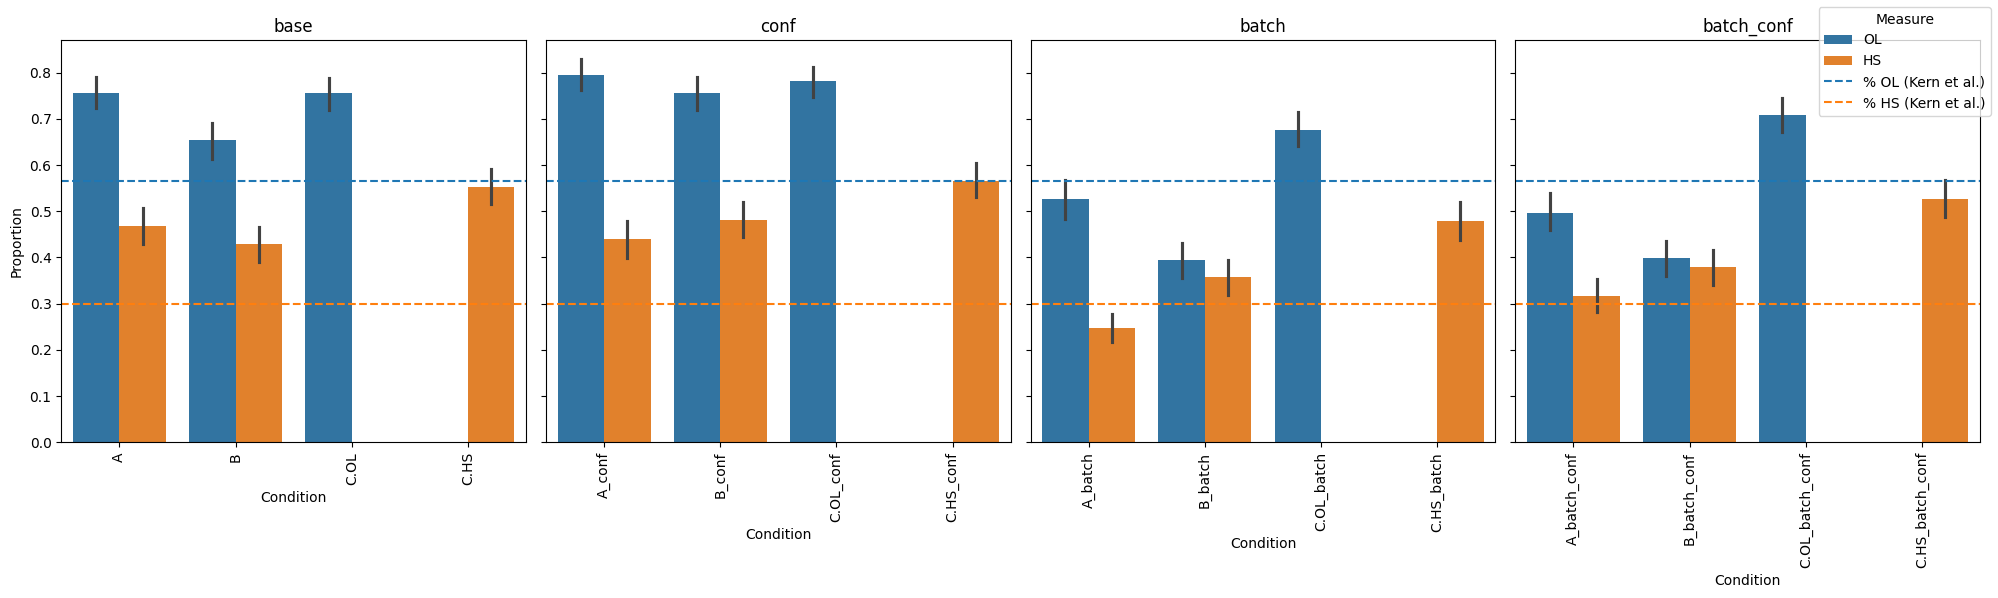

In [61]:
# Optionally, extract the base condition (everything before any underscore).
df = df_long.copy()
df['base_condition'] = df['condition'].apply(lambda x: x.split('_')[0])

# use the overall HS/OL from Kern et al. (2023) as comparison
overall_OL = final_summary.loc['overall']['OL']
overall_HS = final_summary.loc['overall']['HS']


# A custom function to extract the correct group type.
def extract_group_type(x):
    if '_' not in x:
        return 'base'
    elif x.endswith('_batch_conf'):
        return 'batch_conf'
    elif x.endswith('_conf'):
        return 'conf'
    elif x.endswith('_batch'):
        return 'batch'
    else:
        return 'other'

# Create a column for the group type.
df['group_type'] = df['condition'].apply(extract_group_type)

# Melt the DataFrame to have one row per condition-measure combination.
df_melt = df.melt(
    id_vars=['condition', 'base_condition', 'group_type'],
    value_vars=['OL', 'HS'],
    var_name='Measure',
    value_name='Value'
)

# Define the desired order for our groups.
group_order = ['base', 'conf', 'batch', 'batch_conf']

# Create subplots – one subplot per group type.
fig, axes = plt.subplots(nrows=1, ncols=len(group_order), figsize=(20, 6), sharey=True)


for ax, grp in zip(axes, group_order):
    # Subset data for the current group type.
    df_grp = df_melt[df_melt['group_type'] == grp]
    
    # Create the order for conditions for the current group.
    if grp == 'base':
        cond_order = [cond for cond in custom_order if '_' not in cond]
    elif grp == 'conf':
        # Select conditions that end with '_conf' but NOT with '_batch_conf'
        cond_order = [cond for cond in custom_order if cond.endswith('_conf') and not cond.endswith('_batch_conf')]
    elif grp == 'batch':
        # Select conditions that end with '_batch' (and not batch_conf because that is handled separately)
        cond_order = [cond for cond in custom_order if cond.endswith('_batch') and not cond.endswith('_batch_conf')]
    elif grp == 'batch_conf':
        cond_order = [cond for cond in custom_order if cond.endswith('_batch_conf')]
    
    # Plot the grouped barplot for this subgroup.
    sns.barplot(
        data=df_grp,
        x='condition',
        y='Value',
        hue='Measure',
        order=cond_order,  # custom order
        dodge=True,
        ax=ax, 
        palette = {'OL': '#1f77b4', # hex colors as of jacobs paper
                   'HS': '#ff7f0e'}
    )
    
    # Add a dashed horizontal line for overall OL and HS.
    # Using the same colors as defined in the palette.
    ax.axhline(y=overall_OL, linestyle="--", color="#1f77b4", label="% OL (Kern et al.)")
    ax.axhline(y=overall_HS, linestyle="--", color="#ff7f0e", label="% HS (Kern et al.)")
    
    ax.set_title(grp)
    ax.set_xlabel("Condition")
    ax.tick_params(axis='x', rotation=90)
    ax.legend().remove()

# Set a common y-axis label.
axes[0].set_ylabel("Proportion")

# Add a single common legend.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Measure", loc="upper right")

plt.tight_layout()
plt.show()

Notes to the above, it seems as:  
- labelling proportions are by far higher than in the Kern et al Paper
- asking for a confidence score in general increases the OS/HS labelling probability
- using batch prompting in general decreases the labelling probability (rather strong) 

## Rater Agreement of GPT and Kern Labelers

TODO: Check which agreement values to calculate
Currently: Fleiss' Kappa on Diagonal (as there are 3 raters)  
and Cohen's Kappa on the Off Diagonal (as there are always 2 modal ratings per tweet)

In [65]:
# for each tweet and each condition, calculate: 
# 1) Mode for HS and OL
# 2) Mean for HS and OL 
# 3) SD for HS/OL ratings 

from utils import mode_value

tweet_level_df = (df_long
                  .groupby(['tweet_id', 'condition', 
                             'batch_id', 'tweet_in_batch'])
                  .agg(
                        label_count = ('tweet_id', 'count'),
                        HS_mode = ('HS', mode_value),
                        HS_mean = ('HS', 'mean'),
                        HS_std = ('HS', 'std'),
                        OL_mode = ('OL', mode_value),
                        OL_mean = ('OL', 'mean'),
                        OL_std = ('OL', 'std')
).reset_index())

df_long.head(2) # one row per respondent 
print(f'Rows df_long: {df_long.shape[0]}')
print(f'Rows tweet_level_df: {tweet_level_df.shape[0]}')
tweet_level_df.head(2) # one row per tweet x condition

Rows df_long: 9600
Rows tweet_level_df: 3200


,tweet_id,condition,batch_id,tweet_in_batch,label_count,HS_mode,HS_mean,HS_std,OL_mode,OL_mean,OL_std
0,7,A,132,3,3,0,0.0,0.0,1,1.0,0.0
1,7,A_batch,132,3,3,0,0.0,0.0,1,1.0,0.0


### Calculate the Multiple Rater Agreements witihin Condition & Tweet (Fleiss' Kappa)
### Calculate the Modal Label Agreement across Conditions (Cohens Kappa)

In [66]:
import numpy as np
import pandas as pd
import itertools
from utils import mode_value
from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.inter_rater import fleiss_kappa

# -------------------------------
# Helper Functions
# -------------------------------

# (Optional) Original pairwise agreement function (not used in our final diagonal computation)
def pair_agreement(ratings):
    # Get all unique pairs 
    pairs = list(itertools.combinations(ratings, 2))
    # For each pair, check if the two ratings are equal: assign 1 if yes, 0 if not.
    agreements = [1 if a == b else 0 for a, b in pairs]
    return np.mean(agreements)

# Compute Fleiss' Kappa per condition using the raw ratings from df_long.
def compute_fleiss_for_condition(df, condition, rating_column='HS'):
    # Filter raw ratings for the given condition.
    sub = df[df['condition'] == condition]
    # Get all unique rating categories (for example, if ratings are 0 and 1)
    categories = sorted(df[rating_column].dropna().unique())
    # Pivot the data so rows are tweet_ids and columns are rating categories.
    pivot = sub.pivot_table(index='tweet_id', 
                            columns=rating_column, 
                            aggfunc='size', 
                            fill_value=0)
    # Ensure that every expected category appears in the pivot table.
    for cat in categories:
        if cat not in pivot.columns:
            pivot[cat] = 0
    pivot = pivot[categories]  # re-order columns in ascending order
    M = pivot.to_numpy()
    if M.shape[0] == 0:
        return np.nan
    # Use the prepackaged fleiss_kappa from statsmodels.
    return fleiss_kappa(M)

# Compute across-condition agreement using Cohen's Kappa on modal ratings.
def across_agreement(agg_df, cond1, cond2, measure):
    # "measure" should be either 'HS' or 'OL'.
    col_modal = f'modal_{measure}'
    # Extract modal ratings for each condition from the aggregated DataFrame.
    df1 = agg_df[agg_df['condition'] == cond1][['tweet_id', col_modal]].rename(
        columns={col_modal: f'{col_modal}_{cond1}'}
    )
    df2 = agg_df[agg_df['condition'] == cond2][['tweet_id', col_modal]].rename(
        columns={col_modal: f'{col_modal}_{cond2}'}
    )
    # Merge on tweet_id so only tweets rated under both conditions are compared.
    merged = pd.merge(df1, df2, on='tweet_id')
    if merged.empty:
        return np.nan
    # Compute Cohen's kappa between the two sets of modal ratings.
    return cohen_kappa_score(
        merged[f'{col_modal}_{cond1}'], 
        merged[f'{col_modal}_{cond2}']
    )

# -------------------------------
# Step 1: Aggregate Ratings per Tweet per Condition
# -------------------------------
# For each tweet and condition we compute:
#   - The modal rating for HS and for OL.
#   - Also, we still compute within-tweet agreement using pair_agreement if needed.
df_agg = df_long.groupby(['tweet_id', 'condition']).agg(
    modal_HS = ('HS', mode_value),
    agreement_HS = ('HS', lambda x: pair_agreement(list(x))),
    modal_OL = ('OL', mode_value),
    agreement_OL = ('OL', lambda x: pair_agreement(list(x)))
).reset_index()

# -------------------------------
# Step 2: Compute the Across-Condition Agreement Matrices
# -------------------------------
# Get the list of conditions.
conditions = sorted(df_long['condition'].unique())

# Prepare two empty DataFrames for the agreement matrices (one for HS and one for OL).
across_HS = pd.DataFrame(index=conditions, columns=conditions, dtype=float)
across_OL = pd.DataFrame(index=conditions, columns=conditions, dtype=float)

# For each pair of conditions, fill the matrix:
for cond_i in conditions:
    for cond_j in conditions:
        if cond_i == cond_j:
            # Diagonals: Compute Fleiss' kappa on the raw ratings from df_long.
            across_HS.loc[cond_i, cond_j] = compute_fleiss_for_condition(df_long, cond_i, rating_column='HS')
            across_OL.loc[cond_i, cond_j] = compute_fleiss_for_condition(df_long, cond_i, rating_column='OL')
        else:
            # Off-diagonals: Compute Cohen's kappa on the modal ratings from df_agg.
            across_HS.loc[cond_i, cond_j] = across_agreement(df_agg, cond_i, cond_j, 'HS')
            across_OL.loc[cond_i, cond_j] = across_agreement(df_agg, cond_i, cond_j, 'OL')

# -------------------------------
# Results
# -------------------------------
# print("Agreement Matrix for HS (Diagonal: Fleiss' Kappa, Off-diagonal: Cohen's Kappa):")
# print(across_HS)

# print("\nAgreement Matrix for OL (Diagonal: Fleiss' Kappa, Off-diagonal: Cohen's Kappa):")
# print(across_OL)


/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/statsmodels/stats/inter_rater.py:267: RuntimeWarning: invalid value encountered in scalar divide
  kappa = (p_mean - p_mean_exp) / (1- p_mean_exp)
/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:697: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)
/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:697: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)
/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:697: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)
/Users/thomasreiter/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:697: RuntimeWarning: invalid value encountered in

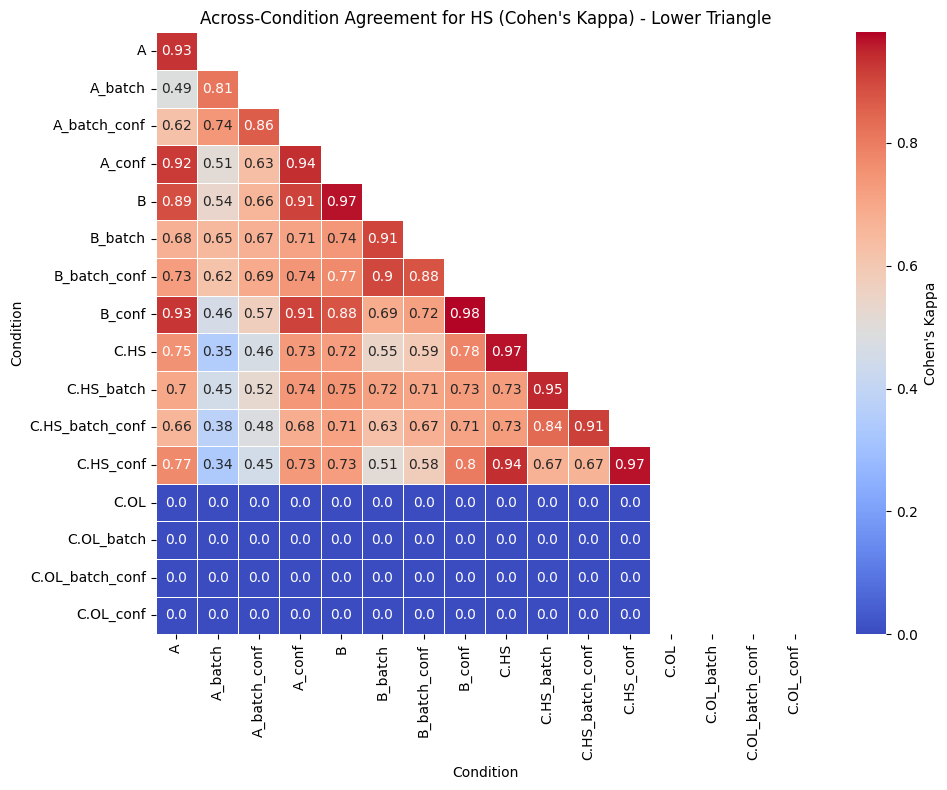

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure across_HS is in float format.
across_HS = across_HS.astype(float)

# Create a boolean mask for the upper triangle.
# np.triu returns the upper triangle of an array.
# Here, k=1 masks everything above the diagonal (the diagonal is unmasked).
mask = np.triu(np.ones_like(across_HS, dtype=bool), k=1)

# Pre-format annotation values:
# - Round the values to two decimals,
# - Convert them to strings,
# - And replace cells that are masked with an empty string.
annot = across_HS.copy().round(2).astype(str)
annot = annot.where(~mask, "")

plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    across_HS,
    mask=mask,
    annot=annot,
    fmt="",   # no additional formatting is necessary since we've pre-formatted
    cmap="coolwarm",
    cbar_kws={'label': "Cohen's Kappa"},
    linewidths=0.5
)

# Move x-axis tick labels to the bottom and rotate them by 90 degrees.
ax.xaxis.tick_bottom()
plt.xticks(rotation=90)

plt.xlabel("Condition")
plt.ylabel("Condition")
plt.title("Across-Condition Agreement for HS (Cohen's Kappa) - Lower Triangle")

plt.tight_layout()
plt.show()


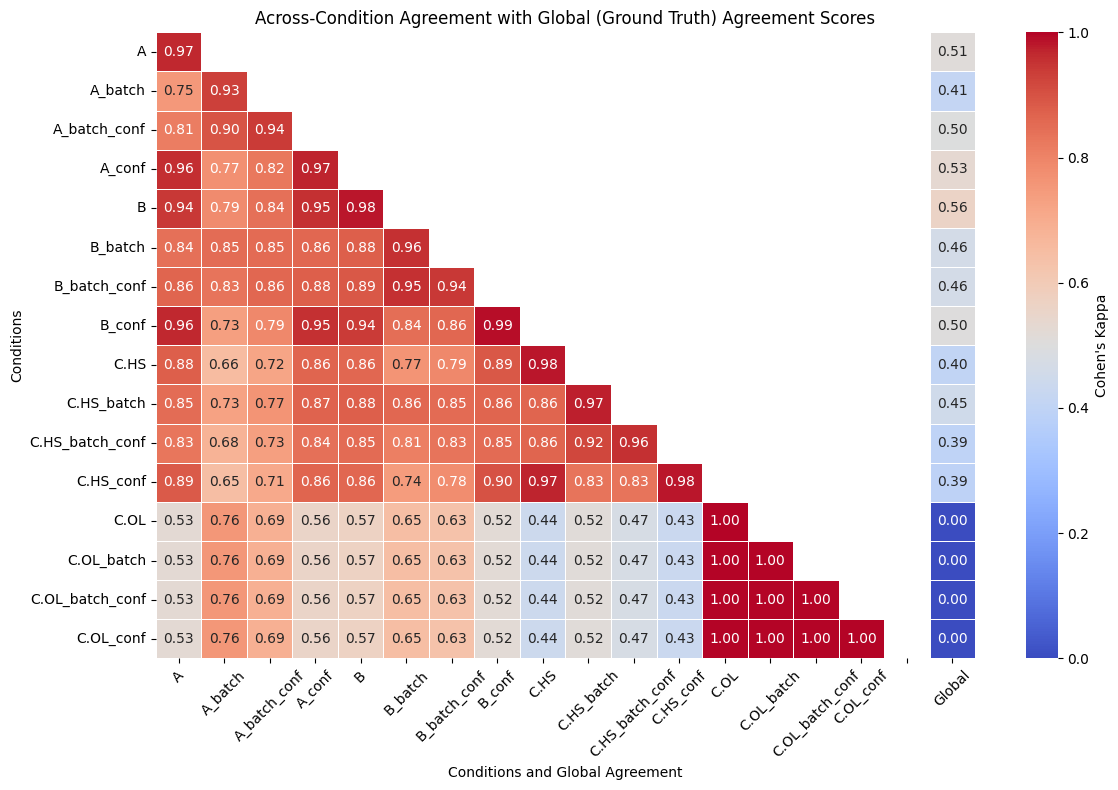

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import cohen_kappa_score

########################################
# STEP 1: Compute the Global Mode from tweets_full
########################################
# Define your mode function (if not already defined).
def mode_value(series):
    modes = series.mode()
    return modes.iloc[0] if not modes.empty else np.nan

# Compute the overall (global) mode for each tweet (ignoring condition).
# This uses all available ratings (expected 15 per tweet).
global_HS = tweets_full.groupby('tweet_id')['hate_speech'].agg(mode_value)
# global_HS is a Series indexed by tweet_id containing the overall mode rating for HS.

########################################
# STEP 2: Prepare the Aggregated Data (df_agg)
########################################
# You mentioned that df_agg is created like this:
#
# df_agg = df_long.groupby(['tweet_id', 'condition']).agg(
#     modal_HS = ('HS', mode_value),
#     agreement_HS = ('HS', lambda x: pair_agreement(list(x))),
#     modal_OL = ('OL', mode_value),
#     agreement_OL = ('OL', lambda x: pair_agreement(list(x)))
# ).reset_index()
#
# We assume that df_agg now contains one row per tweet per condition,
# with the column 'modal_HS' for the condition-specific mode.
#
# For the purpose of comparing the ground truth (global_HS) with the condition-specific modal_HS,
# map the global mode into df_agg using tweet_id:
df_agg['global_HS'] = df_agg['tweet_id'].map(global_HS)

########################################
# STEP 3: Calculate Agreement (Cohen's Kappa) per Condition
########################################
# For each condition, compute Cohen's kappa between:
#   - The global mode rating (from tweets_full, now in df_agg['global_HS'])
#   - The condition-specific mode rating (df_agg['modal_HS'])
kappa_dict = {}

# Iterate over each unique condition present in df_agg.
for cond in df_agg['condition'].unique():
    # Filter to rows for this condition.
    df_cond = df_agg[df_agg['condition'] == cond]
    
    # Select only tweets that have non-missing values for both global and condition-specific ratings.
    valid = df_cond['global_HS'].notna() & df_cond['modal_HS'].notna()
    if valid.sum() > 0:
        kappa = cohen_kappa_score(df_cond.loc[valid, 'global_HS'],
                                  df_cond.loc[valid, 'modal_HS'])
    else:
        kappa = np.nan
    kappa_dict[cond] = kappa

# Convert the agreement scores into a Series indexed by condition.
global_kappa_series = pd.Series(kappa_dict)

########################################
# STEP 4: Combine with the Existing Agreement Matrix (across_HS)
########################################
# Assume across_HS is an existing square DataFrame whose rows and columns are condition names
# with pairwise agreement values among the conditions.
#
# We add a new column that contains the global agreement (Cohen's kappa between the
# global mode and the condition-specific mode for each condition).
combined_matrix = across_HS.copy()

# Align the calculated kappa scores by condition.
# Note: global_kappa_series must have indices that match the condition labels used in across_HS.
combined_matrix['Global'] = global_kappa_series

# Insert a gap column (filled with NaN values) for visual separation.
gap_col_name = ""
# Use the original condition columns order from across_HS:
original_conditions = list(across_HS.columns)
# Insert the gap between the original condition columns and the new "Global" column.
combined_matrix[gap_col_name] = np.nan
# New order: original conditions, gap, then Global.
combined_matrix = combined_matrix[ original_conditions + [gap_col_name, 'Global'] ]

########################################
# STEP 5: Plot the Heatmap with Custom Masking
########################################
# Determine the number of original conditions (n)
original_conditions = list(across_HS.columns)  # these were used in combined_matrix
n = len(original_conditions)

# Create a mask array for the combined_matrix.
# The combined_matrix has shape (n, n+2): the first n columns are the original agreement scores,
# and the last two columns are the gap and Global scores.
#
# For the square sub-matrix in the first n columns, we use np.triu to mask the upper triangle (k=1).
mask_sub = np.triu(np.ones((n, n), dtype=bool), k=1)

# For the extra two columns (gap and Global), we want no masking.
mask_extra = np.zeros((n, 2), dtype=bool)

# Concatenate the masks horizontally to match the shape of combined_matrix.
mask = np.hstack([mask_sub, mask_extra])

# Create the heatmap using the custom mask.
cmap = sns.diverging_palette(240, 10, as_cmap=True)
cmap.set_bad(color='white')  # NaN values in the gap will appear white

plt.figure(figsize=(12, 8))
ax = sns.heatmap(
    combined_matrix,
    mask=mask,
    annot=True,     # Display numeric values
    fmt=".2f",      # Format values to 2 decimal places
    cmap='coolwarm',
    cbar_kws={'label': "Cohen's Kappa"},
    linewidths=0.5,
    linecolor='white'
)

# Adjust tick labels and layout.
ax.xaxis.tick_bottom()
plt.xticks(rotation=45)
plt.xlabel("Conditions and Global Agreement")
plt.ylabel("Conditions")
plt.title("Across-Condition Agreement with Global (Ground Truth) Agreement Scores")
plt.tight_layout()
plt.show()

<a id="order_effects"></a>
## Order Effects in Batch Prompting Tasks?

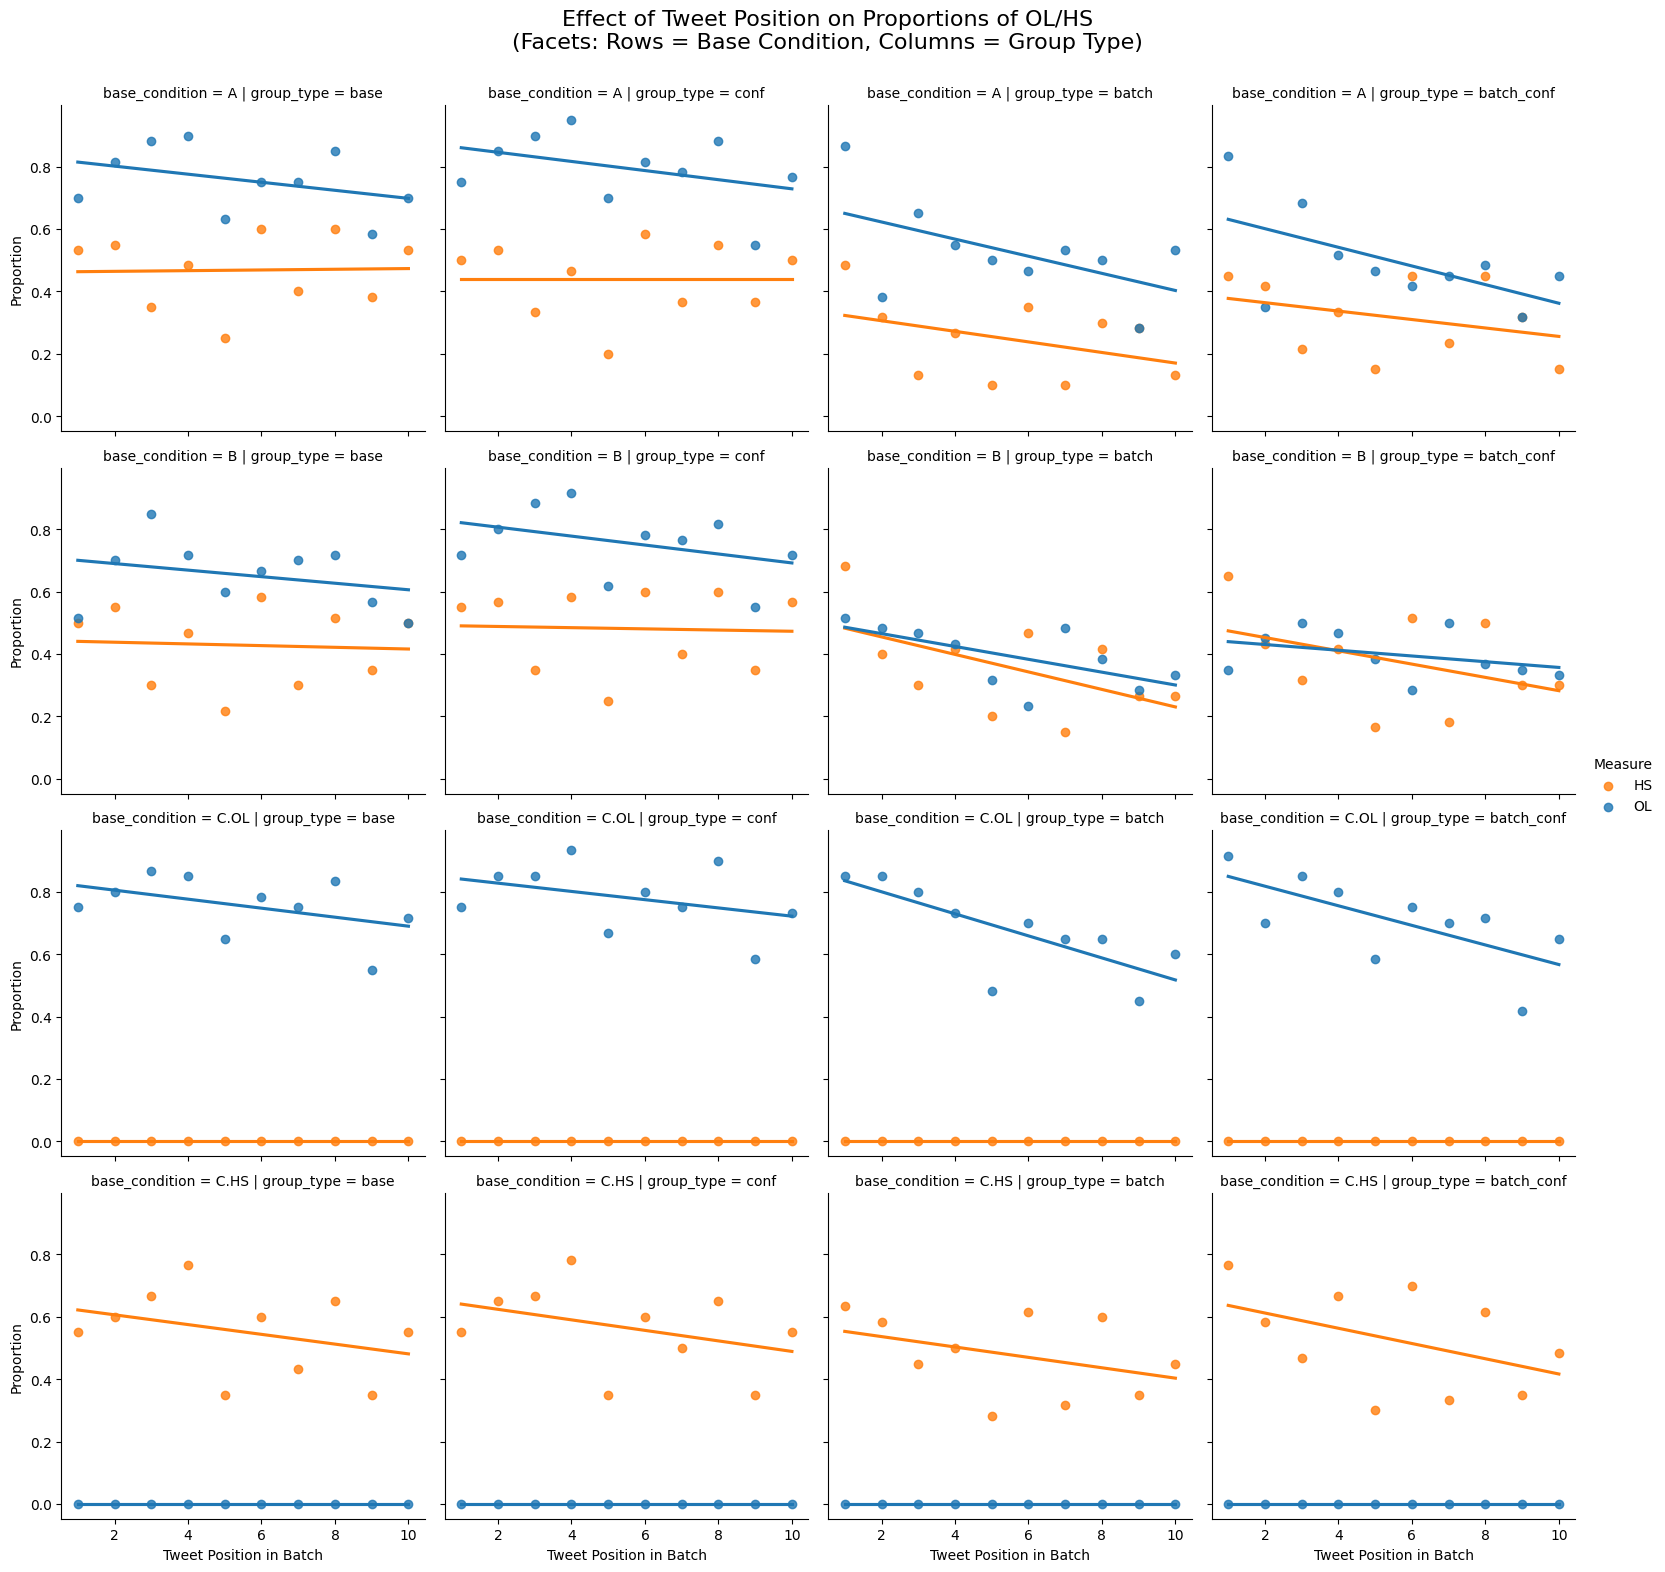

In [78]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------
# 1. Data Preparation
# ---------------------------

# df_long: long --> to 'long long' (also one row per OS and HS)
df_melt = df_long.melt(
    id_vars=['condition', 'tweet_in_batch'],
    value_vars=['OL', 'HS'],
    var_name='Measure',
    value_name='Label'
)

# Group by condition, tweet_in_batch, and measure to compute the proportion
# --> Prop. of Tweets at position X in Condition Y that were labelled as OL / HS
df_prop = df_melt.groupby(
    ['condition', 'tweet_in_batch', 'Measure'], as_index=False
)['Label'].mean()
df_prop.rename(columns={'Label': 'Proportion'}, inplace=True)

# ---------------------------
# 2. Extract Condition Info
# ---------------------------
# Create column for the base condition: if there's an underscore, take the part before it; otherwise, use the whole condition
df_prop['base_condition'] = df_prop['condition'].apply(lambda x: x.split('_')[0])

# custom function to extract group type
# e.g., for "A_batch_conf" we get 'batch_conf'
def extract_group_type(x):
    if '_' not in x:
        return 'base'
    elif x.endswith('_batch_conf'):
        return 'batch_conf'
    elif x.endswith('_conf'):
        return 'conf'
    elif x.endswith('_batch'):
        return 'batch'
    else:
        return 'other'

df_prop['group_type'] = df_prop['condition'].apply(extract_group_type)

# ---------------------------
# 3. Set Custom Order
# ---------------------------
desired_group_order = ['base', 'conf', 'batch', 'batch_conf']
df_prop['group_type'] = pd.Categorical(df_prop['group_type'],
                                       categories=desired_group_order,
                                       ordered=True)

desired_base_order = ['A', 'B', 'C.OL', 'C.HS']
df_prop['base_condition'] = pd.Categorical(df_prop['base_condition'],
                                           categories=desired_base_order,
                                           ordered=True)

# ---------------------------
# 4. Plot with lmplot in a FacetGrid
# ---------------------------
# x: tweet_in_batch ; y: proportion
# Each facet (given by the row and column) will have two regression lines (one per Measure).
g = sns.lmplot(
    data=df_prop,
    x='tweet_in_batch',
    y='Proportion',
    hue='Measure',              # one line for OL and one for HS
    col='group_type',           # Columns: base, conf, batch, batch_conf
    row='base_condition',       # Rows: A, B, C.OL, C.HS
    markers='o',                # Use circles for the data points
    ci=None,                    # Disable the confidence interval shading (adjust if needed)
    height=4,                   # Height of each facet
    aspect=1,                   # Aspect ratio
    order=1,                     # Linear (OLS) regression
    palette = {'OL': '#1f77b4', # hex colors as of jacobs paper
               'HS': '#ff7f0e'}
)

g.set_axis_labels("Tweet Position in Batch", "Proportion")
g.fig.subplots_adjust(top=0.92)
g.fig.suptitle("Effect of Tweet Position on Proportions of OL/HS\n(Facets: Rows = Base Condition, Columns = Group Type)", fontsize=16)

plt.show()
